# 01. Base de conhecimento e busca (itens 02 e 03)

Este notebook mede a **recuperação** do assistente do AlertaBairro:
- a base são os 97 trechos exportados da API (`base/trechos.json`), com dados do Databricks, camada Ouro pública;
- a busca é a mesma BM25 do site (`backend/app/assistente/busca.py`);
- as perguntas são os 50 casos de `avaliacao/casos_teste.jsonl`.

Para reproduzir, rode `python3 avaliacao/recall.py` ou `python3 notebooks/executar_notebook.py notebooks/01_busca_recall.ipynb`.

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(RAIZ / "avaliacao"), str(RAIZ / "backend")]

## 1. Composição da base

In [2]:
from collections import Counter
from comum import carregar_trechos, carregar_casos
trechos = carregar_trechos()
grupos = Counter(t.id.split(":")[0] if not t.id.startswith("doc:") else t.id.split("#")[0] for t in trechos)
print(f"{len(trechos)} trechos")
for g, n in sorted(grupos.items(), key=lambda x: -x[1]):
    print(f"  {g:<26}{n:>3}")
print("\nExemplo:", trechos[2].id, "|", trechos[2].texto[:150], "...")
print("Fonte:  ", trechos[2].fonte)

97 trechos
  sub                        30
  indice                     30
  chuva                      10
  mes                         9
  doc:limites_dos_dados       6
  doc:sobre_o_app             6
  doc:chuva_e_seguranca       4
  kpi                         1
  clima                       1

Exemplo: sub:SAOMIGUELPAULISTA | Segundo a base histórica, a subprefeitura São Miguel Paulista tem 113 registros de alagamento, ocupando a posição 1 entre 30 subprefeituras com regist ...
Fonte:   workspace.alertabairro.ouro_fato_alagamentos_publica, workspace.alertabairro.ouro_dim_subprefeitura (Databricks, consultado em 2026-11-17T23:20:57+00:00)


## 2. Casos de teste com gabarito

In [3]:
casos = carregar_casos()
print(f"{len(casos)} casos")
for cat, n in Counter(c["categoria"] for c in casos).items():
    print(f"  {cat:<14}{n:>3}")
print("\nExemplos:")
for c in (casos[0], casos[16], casos[38], casos[46]):
    print(f"  {c['id']} [{c['categoria']}] {c['pergunta']}\n      trechos-ouro={c['trechos_ouro']} fatos={c['fatos']} deve_recusar={c['deve_recusar']}")

50 casos
  subprefeitura  12
  mes             5
  chuva           5
  resumo          3
  indice          3
  documento       8
  nao_consta     10
  previsao        3
  emergencia      1

Exemplos:
  T01 [subprefeitura] Quantos alagamentos foram registrados na subprefeitura de São Miguel Paulista em 2026, segundo a base da Defesa Civil de São Paulo?
      trechos-ouro=['sub:SAOMIGUELPAULISTA', 'indice:SAOMIGUELPAULISTA'] fatos=['113'] deve_recusar=False
  T17 [mes] Por que julho não aparece no gráfico mensal de alagamentos?
      trechos-ouro=['mes:2026-07', 'doc:limites_dos_dados#4'] fatos=['lacuna'] deve_recusar=False
  T39 [nao_consta] Quanto choveu em 15/10/2026?
      trechos-ouro=[] fatos=[] deve_recusar=True
  T47 [previsao] Vai alagar em São Miguel Paulista amanhã?
      trechos-ouro=[] fatos=[] deve_recusar=True


## 3. recall@1 e recall@3

In [4]:
from recall import avaliar
r = avaliar()
print(f"Avaliadas na busca: {r['avaliados_na_busca']} perguntas com resposta "
      f"(as barradas antes da busca pelo guardrail: {', '.join(r['barrados_pelo_guardrail'])})")
print(f"recall@1 = {r['recall_1']:.1%}")
print(f"recall@3 = {r['recall_3']:.1%}")
print("\nFora do top-3:")
for e in r["erros_top3"]:
    print(f"  {e['id']} ({e['categoria']}): top-3 = {e['top3']}")

Avaliadas na busca: 35 perguntas com resposta (as barradas antes da busca pelo guardrail: T10, T47, T48, T49, T50)
recall@1 = 94.3%
recall@3 = 94.3%

Fora do top-3:
  T22 (chuva): top-3 = ['chuva:2026-10-28', 'chuva:2026-10-30', 'chuva:2026-10-31']
  T24 (resumo): top-3 = ['sub:SE', 'sub:IPIRANGA', 'sub:BUTANTA']


## 4. Escolha do limiar

O site só aceita o melhor trecho quando **score BM25 ≥ limiar** e quando ele cobre os termos da pergunta: **pelo menos 2 termos casados, ou metade dos termos**. A curva abaixo varia o score mínimo e mostra o efeito em dois grupos:
- quanto das perguntas **com resposta** segue aceito;
- quantas perguntas **"não consta"** passam indevidamente.

limiar |  com resposta aceitas | não consta aceitas
   0.0 |                100.0% |              70.0%
   1.0 |                100.0% |              70.0%
   1.5 |                100.0% |              70.0%
   2.0 |                100.0% |              70.0%
   2.5 |                100.0% |              70.0%
   3.0 |                100.0% |              70.0%
   4.0 |                 94.3% |              60.0%
   5.0 |                 88.6% |              50.0%
   6.0 |                 82.9% |              40.0%

Menor score top-1 entre perguntas com resposta: 3.40
Maior score top-1 entre 'não consta':           11.41


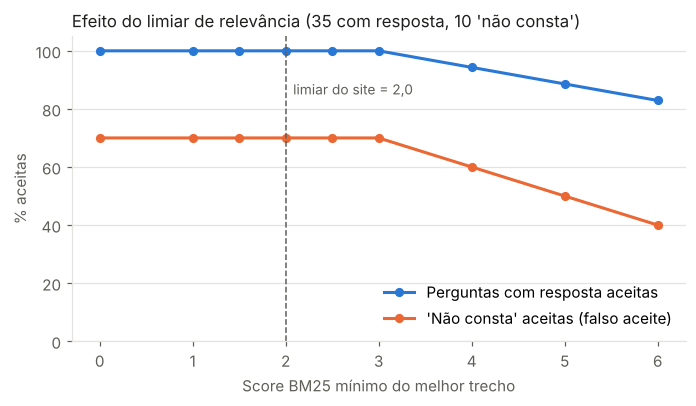

In [5]:
import matplotlib.pyplot as plt
# Paleta categórica validada (azul, laranja, verde-água) e tinta de texto neutra
CORES = {"sem_contexto": "#2a78d6", "rag": "#eb6834", "lora_rag": "#1baf7a"}
TINTA, TINTA_2, GRADE = "#1f1f1e", "#5f5e58", "#e4e3df"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": GRADE, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2,
                     "ytick.color": TINTA_2, "axes.spines.top": False, "axes.spines.right": False, "axes.titlecolor": TINTA})

curva = r["curva_limiar"]
xs = [c["limiar"] for c in curva]
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.plot(xs, [c["respondiveis_aceitas"] * 100 for c in curva], color="#2a78d6", lw=2, marker="o", ms=5, label="Perguntas com resposta aceitas")
ax.plot(xs, [c["nao_consta_aceitas"] * 100 for c in curva], color="#eb6834", lw=2, marker="o", ms=5, label="'Não consta' aceitas (falso aceite)")
ax.axvline(2.0, color=TINTA_2, lw=1, ls="--")
ax.text(2.08, 85, "limiar do site = 2,0", color=TINTA_2, fontsize=9)
ax.set_xlabel("Score BM25 mínimo do melhor trecho")
ax.set_ylabel("% aceitas")
ax.set_ylim(0, 105)
ax.grid(axis="y", color=GRADE, lw=0.8)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Efeito do limiar de relevância (35 com resposta, 10 'não consta')", loc="left", fontsize=11)
print(f"{'limiar':>6} | {'com resposta aceitas':>21} | {'não consta aceitas':>18}")
for c in curva:
    print(f"{c['limiar']:>6} | {c['respondiveis_aceitas']:>21.1%} | {c['nao_consta_aceitas']:>18.1%}")
print(f"\nMenor score top-1 entre perguntas com resposta: {r['menor_score_respondivel']:.2f}")
print(f"Maior score top-1 entre 'não consta':           {r['maior_score_nao_consta']:.2f}")

**Interpretação.**
- **Por que 2,0:** a menor nota entre as perguntas com resposta é 3,40. O limiar de 2,0 fica abaixo dela com folga, então **não perde nenhuma pergunta respondível**. Subir o limiar para 4 já descarta 5,7% delas.
- **O que o limiar barra:** perguntas fora do assunto, como "rio Tietê", "seguro" e "Guarulhos". Quem barra essas é a regra de cobertura.
- **O que ele não barra:** as perguntas "não consta" que usam o vocabulário da base, como "Parelheiros em 2025" ou "chuva em 15/10/2026", chegam a ter **score maior que perguntas legítimas** (até 11,4). Uma busca lexical não separa esses casos. Por isso a **recusa delas fica com o modelo**, e é isso que o placar (notebook 03) mede.